## This script measures risk adjusted performance of stocks of AAPL by calculating Sharpe ratio, Treynor ratio, and Sortino ratio. I will define the ratios and their significance as we calculate them.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import pandas as pd
import yfinance as yf

### Load historical data of stocks of AAPL starting from date (YYYY-MM-DD) 2021-01-04 to end date 2025-12-31 as a csv file.

In [3]:
stocks = {
    "^GSPC": "SP500.csv",
    "AAPL": "AAPL.csv",
    "MSFT": "MSFT.csv",
}
download_stocks = True
data={}

## Download AAPL data
if(download_stocks):
    for ticker, filename in stocks.items():
        print(ticker)
        data[ticker] = yf.download(ticker,start="2021-01-01",end="2026-01-01",auto_adjust=False)
        data[ticker].to_csv(filename)

# Download S&P 500 data
# sp500_data = yf.download("^GSPC", start="2021-01-01", end="2026-01-01", auto_adjust = False)
# sp500_data.to_csv("SP500.csv")
# print(sp500_data.head())

^GSPC


[*********************100%***********************]  1 of 1 completed


AAPL


[*********************100%***********************]  1 of 1 completed


MSFT


[*********************100%***********************]  1 of 1 completed


### We need to clean data first. First two rows are irrelevant. Convert strings into numerics, and setting date of trading as an index of data.

In [3]:
## Read the data
aapl = pd.read_csv("AAPL.csv")

## Remove first 2 rows because actual data starts from row 2.
aapl = aapl.iloc[2:]

## Set date as the index of the dataframe
aapl["Price"] = pd.to_datetime(aapl["Price"])
aapl = aapl.set_index("Price")
aapl.index.rename("Date", inplace=True)

### Convert string values of Adjusted closing price of a stock to numeric 
aapl["Adj Close"] = pd.to_numeric(aapl["Adj Close"])
print(aapl.head())

             Adj Close               Close                High  \
Date                                                             
2021-01-04  125.632523  129.41000366210938  133.61000061035156   
2021-01-05  127.185776  131.00999450683594  131.74000549316406   
2021-01-06  122.904533   126.5999984741211   131.0500030517578   
2021-01-07  127.098427   130.9199981689453   131.6300048828125   
2021-01-08  128.195404   132.0500030517578   132.6300048828125   

                           Low                Open     Volume  
Date                                                           
2021-01-04  126.76000213623047  133.52000427246094  143301900  
2021-01-05  128.42999267578125  128.88999938964844   97664900  
2021-01-06  126.37999725341797  127.72000122070312  155088000  
2021-01-07  127.86000061035156  128.36000061035156  109578200  
2021-01-08  130.22999572753906  132.42999267578125  105158200  


## Calculate daily returns $$R_d = (P_t - P_{t-1})/P_{t-1}$$, where $P_t$ = Adjusted closing price on day 't', $P_{t-1}$ = Adjusted closing price on day 't-1'.

0.0007667698922656968 0.017551813119970863


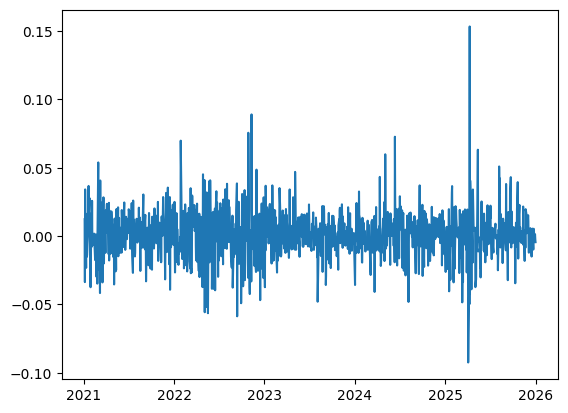

In [4]:
aapl["returns"] = aapl["Adj Close"].pct_change()
avgreturn = aapl["returns"].mean()
stdreturn = aapl["returns"].std()
print(avgreturn, stdreturn)
plt.plot(aapl["returns"])

aapl = aapl.dropna()

### Now, load the 3-month US Treasury bill annualized data to calculate daily risk-free returns from annual rate using compounding interest over 252 trading days in a year. $$rate_d = (1 + rate_A)^{1/252} - 1$$ where $rate_d$ is the daily risk-free return, and $rate_A$ is the annual risk-free return.

In [16]:
riskfree = pd.read_csv("DGS3MO.csv")
riskfree["observation_date"] = pd.to_datetime(riskfree["observation_date"])
riskfree = riskfree.set_index("observation_date")
print(riskfree)

## Check for missing dates in aapl and risk-free return data
missing_dates_data = aapl.index.difference(riskfree.index)
print(missing_dates_data)
missing_dates_rf = riskfree.index.difference(aapl.index)
print(missing_dates_rf)
merge_data = pd.merge(aapl, riskfree, how='left', left_index=True, right_index=True) 

## Calculate daily risk-free return
merge_data["rf_daily"] = (1 + merge_data["DGS3MO"])**(1/252) - 1
merge_data

                  DGS3MO
observation_date        
2021-01-04          0.09
2021-01-05          0.09
2021-01-06          0.09
2021-01-07          0.09
2021-01-08          0.08
...                  ...
2025-12-25           NaN
2025-12-26          3.64
2025-12-29          3.68
2025-12-30          3.65
2025-12-31          3.67

[1303 rows x 1 columns]
DatetimeIndex([], dtype='datetime64[ns]', freq=None)
DatetimeIndex(['2021-01-04', '2021-01-18', '2021-02-15', '2021-04-02',
               '2021-05-31', '2021-07-05', '2021-09-06', '2021-11-25',
               '2021-12-24', '2022-01-17', '2022-02-21', '2022-04-15',
               '2022-05-30', '2022-06-20', '2022-07-04', '2022-09-05',
               '2022-11-24', '2022-12-26', '2023-01-02', '2023-01-16',
               '2023-02-20', '2023-04-07', '2023-05-29', '2023-06-19',
               '2023-07-04', '2023-09-04', '2023-11-23', '2023-12-25',
               '2024-01-01', '2024-01-15', '2024-02-19', '2024-03-29',
               '2024-05-27', 

,Adj Close,Close,High,Low,Open,Volume,returns,DGS3MO,rf_daily
Date,,,,,,,,,
2021-01-05,127.185776,131.00999450683594,131.74000549316406,128.42999267578125,128.88999938964844,97664900,0.012363,0.09,0.000342
2021-01-06,122.904533,126.5999984741211,131.0500030517578,126.37999725341797,127.72000122070312,155088000,-0.033661,0.09,0.000342
2021-01-07,127.098427,130.9199981689453,131.6300048828125,127.86000061035156,128.36000061035156,109578200,0.034123,0.09,0.000342
2021-01-08,128.195404,132.0500030517578,132.6300048828125,130.22999572753906,132.42999267578125,105158200,0.008631,0.08,0.000305
2021-01-11,125.215027,128.97999572753906,130.1699981689453,128.5,129.19000244140625,100384500,-0.023249,0.08,0.000305
...,...,...,...,...,...,...,...,...,...
2025-12-24,273.066711,273.80999755859375,275.42999267578125,272.20001220703125,272.3399963378906,17910600,0.005324,3.69,0.006152
2025-12-26,272.657867,273.3999938964844,275.3699951171875,272.8599853515625,274.1600036621094,21521800,-0.001497,3.64,0.006109
2025-12-29,273.016876,273.760009765625,274.3599853515625,272.3500061035156,272.69000244140625,23715200,0.001317,3.68,0.006143


## Calculate Sharpe ratio, $$S = \langle R_d - R_f \rangle/\sigma_d $$ where $R_d$ is the daily return, $R_f$ is the risk-free return per day, and $\sigma_d$ is the standard deviation of the returns $R_d$. The $\langle \cdot \rangle$ denote the average over the full cycle for which excess return is calculated.  

In [42]:
merge_data["excess_return"] = merge_data["returns"] - merge_data["rf_daily"]
print(merge_data.head())
Sharpe_ratio = merge_data["excess_return"].mean()/merge_data["excess_return"].std()
print(Sharpe_ratio)

             Adj Close               Close                High  \
Date                                                             
2021-01-05  127.185776  131.00999450683594  131.74000549316406   
2021-01-06  122.904533   126.5999984741211   131.0500030517578   
2021-01-07  127.098427   130.9199981689453   131.6300048828125   
2021-01-08  128.195404   132.0500030517578   132.6300048828125   
2021-01-11  125.215027  128.97999572753906   130.1699981689453   

                           Low                Open     Volume   returns  \
Date                                                                      
2021-01-05  128.42999267578125  128.88999938964844   97664900  0.012363   
2021-01-06  126.37999725341797  127.72000122070312  155088000 -0.033661   
2021-01-07  127.86000061035156  128.36000061035156  109578200  0.034123   
2021-01-08  130.22999572753906  132.42999267578125  105158200  0.008631   
2021-01-11               128.5  129.19000244140625  100384500 -0.023249   

           

## Clean S&P 500 data

In [23]:
## Clean S&P 500 data
# sp500_data = sp500_data.iloc
sp500_data = pd.read_csv("SP500.csv")
sp500_data = sp500_data.iloc[2:]

sp500_data["Price"] = pd.to_datetime(sp500_data["Price"])
sp500_data = sp500_data.set_index("Price")
sp500_data.index.rename("Date", inplace = True)

sp500_data["Adj Close"] = pd.to_numeric(sp500_data["Adj Close"])
sp500_data["market return"] = sp500_data["Adj Close"].pct_change()
sp500_data = sp500_data.dropna()
sp500_data

,Adj Close,Close,High,Low,Open,Volume,market return
Date,,,,,,,
2021-01-05,3726.860107,3726.860107421875,3737.830078125,3695.070068359375,3698.02001953125,4591020000,0.007083
2021-01-06,3748.139893,3748.139892578125,3783.0400390625,3705.340087890625,3712.199951171875,6064110000,0.005710
2021-01-07,3803.790039,3803.7900390625,3811.550048828125,3764.7099609375,3764.7099609375,5099160000,0.014847
2021-01-08,3824.679932,3824.679931640625,3826.68994140625,3783.60009765625,3815.050048828125,4773040000,0.005492
2021-01-11,3799.610107,3799.610107421875,3817.860107421875,3789.02001953125,3803.139892578125,4465430000,-0.006555
...,...,...,...,...,...,...,...
2025-12-24,6932.049805,6932.0498046875,6937.31982421875,6904.91015625,6904.91015625,1798270000,0.003221
2025-12-26,6929.939941,6929.93994140625,6945.77001953125,6921.60009765625,6936.02001953125,2586550000,-0.000304
2025-12-29,6905.740234,6905.740234375,6920.2099609375,6888.759765625,6903.60009765625,3541750000,-0.003492


In [43]:
missing_dates = merge_data.index.difference(sp500_data.index)
print(missing_dates)
missing_dates = sp500_data.index.difference(merge_data.index)
print(missing_dates)

merge_aapl_rf_sp500 = pd.merge(merge_data, sp500_data, how='left', left_index = True, right_index = True)
print(merge_aapl_rf_sp500.head())

risk_data = merge_aapl_rf_sp500[["returns", "excess_return", "rf_daily","market return"]].copy()
risk_data = risk_data.rename(columns={"returns": "aapl_return", "excess_return": "aapl_excess_return",
    "market return": "market_return"})
risk_data.head()

DatetimeIndex([], dtype='datetime64[ns]', name='Date', freq=None)
DatetimeIndex([], dtype='datetime64[ns]', name='Date', freq=None)
            Adj Close_x             Close_x              High_x  \
Date                                                              
2021-01-05   127.185776  131.00999450683594  131.74000549316406   
2021-01-06   122.904533   126.5999984741211   131.0500030517578   
2021-01-07   127.098427   130.9199981689453   131.6300048828125   
2021-01-08   128.195404   132.0500030517578   132.6300048828125   
2021-01-11   125.215027  128.97999572753906   130.1699981689453   

                         Low_x              Open_x   Volume_x   returns  \
Date                                                                      
2021-01-05  128.42999267578125  128.88999938964844   97664900  0.012363   
2021-01-06  126.37999725341797  127.72000122070312  155088000 -0.033661   
2021-01-07  127.86000061035156  128.36000061035156  109578200  0.034123   
2021-01-08  130.2299957

,aapl_return,aapl_excess_return,rf_daily,market_return
Date,,,,
2021-01-05,0.012363,0.012021,0.000342,0.007083
2021-01-06,-0.033661,-0.034003,0.000342,0.005710
2021-01-07,0.034123,0.033781,0.000342,0.014847
2021-01-08,0.008631,0.008325,0.000305,0.005492
2021-01-11,-0.023249,-0.023554,0.000305,-0.006555


## Calculate the Treynor ratio,

$$
T = \frac{\langle R_d - R_f \rangle}{\beta},
$$

where

$$
\beta = \frac{\operatorname{Cov}(R_d,R_m)}
{\operatorname{Var}(R_m)}.
$$

Here, $\beta$ measures the sensitivity of the asset's daily returns $(R_d)$ to market returns $(R_m)$. A positive $\beta$ indicates that the asset generally moves in the same direction as the market, while a negative \(\beta\) indicates that it tends to move in the opposite direction. A larger magnitude of $\beta$ indicates greater sensitivity to market movements.

The Treynor ratio therefore measures the **excess return generated per unit of systematic (market) risk**.

In [2]:
covariance = risk_data["aapl_return"].cov(risk_data["market_return"])
market_variance = risk_data["market_return"].var()

beta = covariance / market_variance

print(r'$\beta$:',beta)
Treynor_ratio = risk_data["aapl_excess_return"].mean()/beta
print(r'Treynor ratio:',Treynor_ratio)

NameError: name 'risk_data' is not defined